# Random Forest Regressor — Harga Rekomendasi SPK Smartphone Bekas

**Alur:**
1. Load dataset
2. Feature engineering
3. Train Random Forest (target = rasio `harga_rekomendasi_spk / harga_pasaran_medsos`)
4. Evaluasi (cross-validation + hold-out)
5. Simpan model (`.joblib`) untuk dipakai backend website / n8n

Catatan: `harga_pasaran_medsos` adalah **input** model. Nilainya nanti diisi dari hasil scraping n8n.

In [ ]:
# 1. Upload dataset (jalankan sel ini lalu pilih file .xlsx)
from google.colab import files
uploaded = files.upload()
FILE = list(uploaded.keys())[0]
FILE

Saving dataset_smartphone_500_lengkap.xlsx to dataset_smartphone_500_lengkap.xlsx


'dataset_smartphone_500_lengkap.xlsx'

In [ ]:
import pandas as pd, numpy as np, joblib, json
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict, train_test_split, GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

df = pd.read_excel(FILE)
print(df.shape)
df.head()

(520, 14)


,id,brand,model,ram_gb,storage_gb,asal_unit,status_imei,skala_kondisi_fisik,battery_health,riwayat_servis,kelengkapan,garansi_aktif,harga_pasaran_medsos,harga_rekomendasi_spk
0,1,Apple,iPhone X,3,256,Inter / Impor,Bypass,4,81,Ganti Housing,Fullset Original,0,3130000,1630000
1,2,Apple,iPhone X,3,256,Inter / Impor,Simlok / Sinyal Blocked,3,74,Ganti Housing,Fullset Original,0,2750000,1460000
2,3,Apple,iPhone X,3,256,Resmi iBox / Digimap,Resmi Terdaftar,3,90,Original Normal,Batangan,0,2840000,2330000
3,4,Apple,iPhone X,3,256,Resmi iBox / Digimap,Resmi Terdaftar,4,87,Original Normal,Unit + Charger OEM,0,3080000,2830000
4,5,Apple,iPhone XR,3,128,Resmi iBox / Digimap,Resmi Terdaftar,2,92,Servis Mesin / Part Lain,Unit + Charger OEM,0,3740000,2390000


## 2. Feature engineering

In [ ]:
def build_features(d):
    d = d.copy()
    # riwayat_servis berisi beberapa nilai dipisah koma -> multi-hot
    d['svc_lcd']   = d['riwayat_servis'].str.contains('LCD').astype(int)
    d['svc_bat']   = d['riwayat_servis'].str.contains('Baterai').astype(int)
    d['svc_hous']  = d['riwayat_servis'].str.contains('Housing').astype(int)
    d['svc_mesin'] = d['riwayat_servis'].str.contains('Mesin').astype(int)
    d['n_svc']     = d[['svc_lcd','svc_bat','svc_hous','svc_mesin']].sum(axis=1)

    num = ['ram_gb','storage_gb','skala_kondisi_fisik','battery_health','garansi_aktif',
           'harga_pasaran_medsos','svc_lcd','svc_bat','svc_hous','svc_mesin','n_svc']
    cat = ['model','asal_unit','status_imei','kelengkapan']   # brand dibuang: sudah terwakili 'model'
    return pd.get_dummies(d[num + cat], columns=cat)

X = build_features(df)
y_price = df['harga_rekomendasi_spk']
y_ratio = y_price / df['harga_pasaran_medsos']
FEATURE_COLUMNS = list(X.columns)
print(X.shape)

(520, 156)


## 3. Training & evaluasi

Target dipilih **rasio** (bukan harga langsung) karena Random Forest tidak bisa memprediksi di luar rentang harga yang pernah dilihat. Dengan rasio, model tetap berjalan wajar untuk HP yang harganya di luar data training. Harga akhir = rasio × harga pasaran.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
def rf(**kw): return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, **kw)

# Pembanding: target harga langsung vs target rasio
p_direct = cross_val_predict(rf(), X, y_price, cv=kf)
p_ratio  = cross_val_predict(rf(), X, y_ratio, cv=kf) * df['harga_pasaran_medsos']

for name, p in [('Target harga langsung', p_direct), ('Target rasio', p_ratio)]:
    print(f"{name:24s} R2={r2_score(y_price,p):.3f}  MAE=Rp{mean_absolute_error(y_price,p):,.0f}  MAPE={mean_absolute_percentage_error(y_price,p)*100:.1f}%")

Target harga langsung    R2=0.939  MAE=Rp473,447  MAPE=10.9%
Target rasio             R2=0.984  MAE=Rp205,399  MAPE=5.0%


In [ ]:
# Tuning ringan (dataset kecil, jadi grid-nya dibuat kecil)
grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    {'n_estimators':[200,400], 'max_depth':[None,8,12], 'min_samples_leaf':[1,2,3], 'max_features':['sqrt',0.5,1.0]},
    cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1)
grid.fit(X, y_ratio)
print(grid.best_params_)

best = grid.best_estimator_
p_best = cross_val_predict(best, X, y_ratio, cv=kf) * df['harga_pasaran_medsos']
print(f"CV  R2={r2_score(y_price,p_best):.3f}  MAE=Rp{mean_absolute_error(y_price,p_best):,.0f}  MAPE={mean_absolute_percentage_error(y_price,p_best)*100:.1f}%")

{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 400}
CV  R2=0.989  MAE=Rp191,658  MAPE=4.8%


Hold-out R2=0.985  MAE=Rp195,043


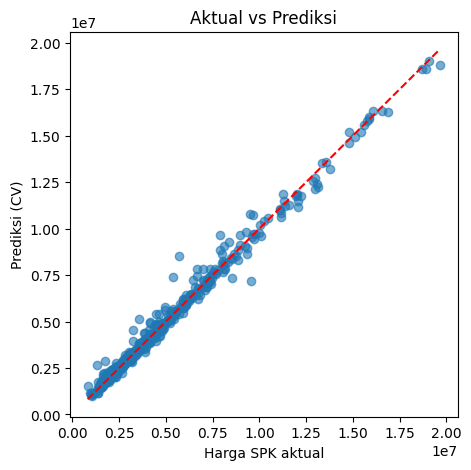

In [ ]:
# Hold-out sanity check
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, random_state=42)
m = RandomForestRegressor(**grid.best_params_, random_state=42).fit(X.loc[idx_tr], y_ratio.loc[idx_tr])
pred = m.predict(X.loc[idx_te]) * df.loc[idx_te,'harga_pasaran_medsos']
print(f"Hold-out R2={r2_score(y_price.loc[idx_te],pred):.3f}  MAE=Rp{mean_absolute_error(y_price.loc[idx_te],pred):,.0f}")

plt.figure(figsize=(5,5))
plt.scatter(y_price, p_best, alpha=.6)
lim=[y_price.min(), y_price.max()]; plt.plot(lim, lim, 'r--')
plt.xlabel('Harga SPK aktual'); plt.ylabel('Prediksi (CV)'); plt.title('Aktual vs Prediksi'); plt.show()

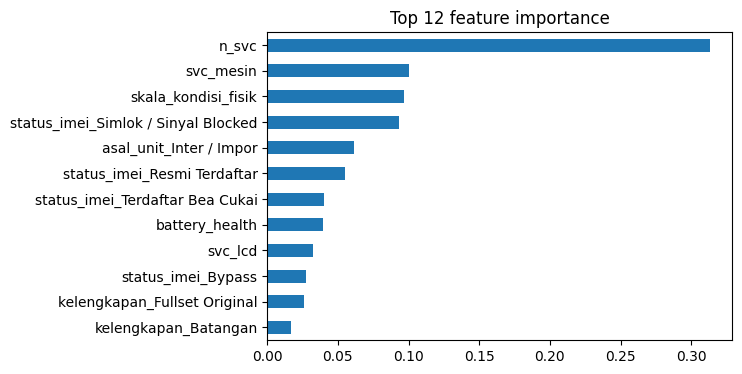

In [ ]:
# Fitur paling berpengaruh
final = RandomForestRegressor(**grid.best_params_, random_state=42).fit(X, y_ratio)
imp = pd.Series(final.feature_importances_, index=FEATURE_COLUMNS).sort_values(ascending=False).head(12)
imp[::-1].plot.barh(figsize=(6,4), title='Top 12 feature importance'); plt.show()

## 4. Simpan model & fungsi prediksi

In [ ]:
joblib.dump({'model': final, 'columns': FEATURE_COLUMNS}, 'rf_harga_spk.joblib')
json.dump(sorted(df['model'].unique().tolist()), open('daftar_model.json','w'))

def prediksi(model_hp, ram_gb, storage_gb, asal_unit, status_imei, skala_kondisi_fisik,
             battery_health, riwayat_servis, kelengkapan, garansi_aktif, harga_pasaran_medsos):
    row = pd.DataFrame([{
        'model': model_hp, 'ram_gb': ram_gb, 'storage_gb': storage_gb, 'asal_unit': asal_unit,
        'status_imei': status_imei, 'skala_kondisi_fisik': skala_kondisi_fisik,
        'battery_health': battery_health, 'riwayat_servis': riwayat_servis,
        'kelengkapan': kelengkapan, 'garansi_aktif': garansi_aktif,
        'harga_pasaran_medsos': harga_pasaran_medsos}])
    Xn = build_features(row).reindex(columns=FEATURE_COLUMNS, fill_value=0)
    rasio = final.predict(Xn)[0]
    # rentang kasar dari sebaran prediksi tiap pohon
    per_tree = np.array([t.predict(Xn.values)[0] for t in final.estimators_]) * harga_pasaran_medsos
    return {'harga_rekomendasi': round(rasio*harga_pasaran_medsos, -4),
            'rentang_bawah': round(np.percentile(per_tree,10), -4),
            'rentang_atas': round(np.percentile(per_tree,90), -4)}

prediksi('Vivo V29', 8, 256, 'Resmi SEIN / Indonesia', 'Resmi Terdaftar', 3, 88,
         'Original Normal', 'Fullset Original', 0, 4500000)

{'harga_rekomendasi': np.float64(4050000.0),
 'rentang_bawah': np.float64(4050000.0),
 'rentang_atas': np.float64(4050000.0)}

In [ ]:
files.download('rf_harga_spk.joblib')
files.download('daftar_model.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>